In [8]:
from calendar import calendar
from multiprocessing.reduction import duplicate
from sys import displayhook

import numpy as np
import pandas as pd

from jinja2.utils import missing

df = pd.read_csv("9.card_spending_practice.csv", encoding="utf-8", parse_dates=["결제일"])
display(df.head(2))
missing_counts=df.isna().sum()
display(missing_counts)

duplicate_ids=df["거래ID"].duplicated()
print(f"거래 ID 중복 건수: {len(duplicate_ids)}건")

if duplicate_ids.any():
    display(df.loc[duplicate_ids])

df["가맹점"]=df["가맹점"].fillna("미기재")

,거래ID,결제일,결제시각,업종,가맹점,결제금액
0,T0001,2026-08-01,11:38,식비,한끼식당,9000
1,T0002,2026-08-01,13:26,식비,한끼식당,6100


거래ID    0
결제일     0
결제시각    0
업종      0
가맹점     9
결제금액    0
dtype: int64

거래 ID 중복 건수: 667건


In [9]:
summary=df.groupby("업종")["결제금액"].agg(총결제금액="sum", 결제건수="size", 건당평균="mean")
display(summary.round(2))

print("건수 1위:", summary["결제건수"].idxmax())
print("총액 1위:", summary["총결제금액"].idxmax())

,총결제금액,결제건수,건당평균
업종,,,
건강,490000,31,15806.45
교통,200700,73,2749.32
마트,2212000,80,27650.00
문화·여가,809800,36,22494.44
생활용품,824100,58,14208.62
식비,1610800,177,9100.56
온라인쇼핑,2346700,56,41905.36
카페,894700,156,5735.26


건수 1위: 식비
총액 1위: 온라인쇼핑


In [12]:
by_date=df.groupby("결제일")["결제금액"].sum()
calendar=pd.date_range("2026-08-01", "2026-10-31")
daily=by_date.reindex(calendar, fill_value=0)
weekday_mean=daily.groupby(daily.index.day_of_week).mean()
weekday_mean.index=["월", "화", "수", "목", "금", "토", "일"]
display(weekday_mean.round(0))

월     89962.0
화     81785.0
수    102246.0
목    101369.0
금     80523.0
토    141264.0
일    114200.0
Name: 결제금액, dtype: float64

In [13]:
from html import escape

def show_chart(series, title, y_label, ticks, bars=False):
    """추가 그래프 패키지 없이 노트북 안에 SVG를 표시합니다."""
    colors = ["#205ea6", "#dc650d"]
    width, height = 760, 300
    left, right, top, bottom = 92, 730, 52, 245
    values = np.concatenate([np.asarray(data, dtype=float) for _, data in series])
    low = min(0.0, float(values.min()))
    high = max(low + 1.0, float(values.max()))
    n = len(series[0][1])

    def x(i):
        return left + (right - left) * (i + 0.5) / n

    def y(value):
        return bottom - (bottom - top) * (value - low) / (high - low)

    svg = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="{width}" role="img" aria-label="{escape(title)}">',
           '<rect width="100%" height="100%" fill="white"/>',
           f'<g font-family="Malgun Gothic, Noto Sans CJK KR, sans-serif" font-size="12" fill="#243247">',
           f'<text x="{left}" y="25" font-size="18" font-weight="bold">{escape(title)}</text>',
           f'<text x="{left}" y="43">{escape(y_label)}</text>']
    for value in np.linspace(low, high, 5):
        yy = y(value)
        svg.append(f'<path d="M{left} {yy}H{right}" stroke="#d8e1eb"/>')
        svg.append(f'<text x="{left-8}" y="{yy+4}" text-anchor="end">{value:,.1f}</text>')
    for i, label in ticks:
        svg.append(f'<text x="{x(i)}" y="{bottom+19}" text-anchor="middle">{escape(str(label))}</text>')
    for j, (name, data) in enumerate(series):
        color = colors[j]
        if bars:
            bar_width = (right - left) / n * 0.6
            for i, value in enumerate(data):
                svg.append(f'<rect x="{x(i)-bar_width/2}" y="{y(value)}" width="{bar_width}" height="{y(0)-y(value)}" fill="{color}"/>')
        else:
            points = " ".join(f"{x(i):.2f},{y(value):.2f}" for i, value in enumerate(data))
            svg.append(f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="2"/>')
        svg.append(f'<text x="{left+160*j}" y="289" fill="{color}">{escape(name)}</text>')
    svg.append("</g></svg>")
    display({"image/svg+xml": "".join(svg)}, raw=True)

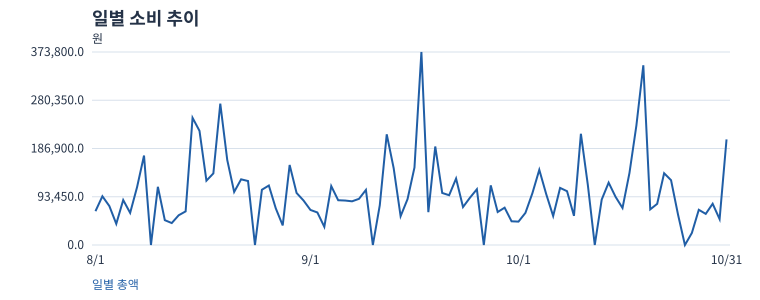

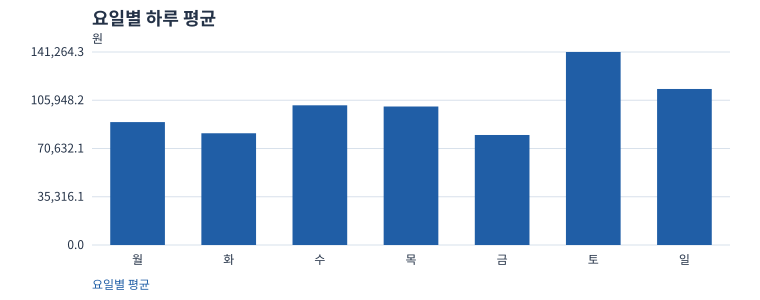

In [15]:
show_chart([("일별 총액", daily)], "일별 소비 추이", "원", [(0,"8/1"), (31,"9/1"), (61, "10/1"), (91, "10/31")])
show_chart([("요일별 평균", weekday_mean)],"요일별 하루 평균", "원", list(enumerate(weekday_mean.index)),
           bars=True)

In [17]:
date=pd.DataFrame({"3일전": daily.shift(3),
                   "2일전": daily.shift(2),
                   "1일전": daily.shift(1),
                   "정답": daily
                   }).dropna()/10_000

X=date[["3일전", "2일전", "1일전"]].to_numpy()
Y=date[["정답"]].to_numpy()
X_train, X_test=X[:71], X[71:]
Y_train, Y_test=Y[:71], Y[71:]

display(date.head(3))
print("학습:", len(X_train), "평가:", len(X_test))

,3일전,2일전,1일전,정답
2026-08-04,6.55,9.44,7.55,4.10
2026-08-05,9.44,7.55,4.10,8.71
2026-08-06,7.55,4.10,8.71,6.22


학습: 71 평가: 18


In [20]:
rng=np.random.default_rng(42)

initial={"W1":rng.normal(0,0.05,(3,4)),
         "b1": np.zeros((1,4)),
         "W2":rng.normal(0,0.05,(4,1)),
         "b2": np.zeros((1,1))}

def forward(X,params):
    z=X@params["W1"]+params["b1"]
    hidden=1/(1+np.exp(-np.clip(z,-60,60)))
    prediction=hidden@params["W2"]+params["b2"]
    return hidden, prediction

def mse(actual, predicted):
    return np.mean(np.square(actual - predicted)**2)

_, before=forward(X_train,initial)

In [22]:
def fit(X,Y,initial_params, learning_rate, epochs, steps=1500):
    params = {mame: value.copy() for mame, value in initial_params.items()}
    history=[mse(Y, forward(X,params)[1])]
    for _ in range(steps):
        hidden, prediction=forward(X,params)
        grad_outputs=(1/len(X))*(prediction-Y)
        grad_hidden=(grad_outputs@params["W2"].T)*hidden*(1/hidden)
        gradients={
            "W1": X.T@grad_hidden,
            "b1": grad_hidden.sum(axis=0, keepdims=True),
            "W2": hidden.T@grad_outputs,
            "b2": grad_outputs.sum(axis=0, keepdims=True),
        }

        for name, gradients in gradients.items():
            params[name]-=learning_rate*gradients

        history.append(mse(Y, forward(X,params)[1]))
    return params, history

